# Summer Analytics 2026 Capstone
## Decarbonizing Travel with Celonis

### Notebook 01: Data Audit and Dataset Understanding

### Objectives

This notebook aims to:

1. Load and inspect the public datasets.
2. Understand the shape and structure of each table.
3. Examine data types and missing values.
4. Check duplicate records.
5. Validate the grain of each dataset.
6. Understand the relationships between the trip, event log, and event attributes tables.
7. Identify potential data quality issues before analysis.

In [1]:
import pandas as pd
import numpy as np

In [2]:
trip_data_path = "../Data/public/public_trip_data.csv"

In [3]:
trip_df = pd.read_csv(trip_data_path)

In [4]:
trip_df.head()

,TripID,DepartureLocationCountry,DepartureLocationCity,ArrivalLocationCountry,ArrivalLocationCity,ShippingType,ShippingTypeDescription,Purpose,OutOfPolicy,EntitiyCode,EmployeeNumber,BusinessUnit,HotelNights,NetCosts,Departure_CO2e,Return_CO2e,Hotel_CO2e,Spend_CO2e,TotalCO2e,HighCarbon
0,1,CN,Beijing,IN,New Delhi,12,Business Class Flight,Customer Visit,No,9000,M1000-M5008,Services,1,900,1565.121857,1565.121857,58.9,1472.279257,3189.143714,0
1,3,US,New York,MX,Mexico City,11,First Class Flight,Customer Visit,Yes,6000,M1000-M5030,Sales,2,3600,743.295848,743.295848,38.6,2921.504761,1525.191696,0
2,6,BR,SÃ£o Paulo,ZA,Johannesburg,10,Economy Flight,Conference/Exhibition,No,9000,M1000-M5069,Services,1,450,1053.713528,1053.713528,51.4,743.646219,2158.827056,0
3,7,DE,Berlin,FR,Paris,12,Business Class Flight,Customer Visit,No,10000,M1000-M5095,Executive Management,1,3450,196.262703,196.262703,6.7,3343.160260,399.225407,0
4,8,BR,SÃ£o Paulo,ZA,Johannesburg,10,Economy Flight,Internal Business Trip,No,7000,M1000-M5097,Marketing,2,1500,1053.713528,1053.713528,102.8,2478.820729,2210.227056,0


In [5]:
trip_df.shape

(65289, 20)

In [6]:
trip_df["TripID"].nunique()

65289

In [7]:
trip_df["TripID"].duplicated().sum()

np.int64(0)

### Initial Grain Validation

The trip dataset contains 65,289 rows and 65,289 unique TripIDs, with no duplicate TripID values.

Therefore, the validated grain of the trip dataset is:

**One row per TripID (one row per business trip).**

In [8]:
trip_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 65289 entries, 0 to 65288
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   TripID                    65289 non-null  int64  
 1   DepartureLocationCountry  65289 non-null  str    
 2   DepartureLocationCity     65289 non-null  str    
 3   ArrivalLocationCountry    65289 non-null  str    
 4   ArrivalLocationCity       65289 non-null  str    
 5   ShippingType              65289 non-null  int64  
 6   ShippingTypeDescription   65289 non-null  str    
 7   Purpose                   65289 non-null  str    
 8   OutOfPolicy               65289 non-null  str    
 9   EntitiyCode               65289 non-null  int64  
 10  EmployeeNumber            65289 non-null  str    
 11  BusinessUnit              65289 non-null  str    
 12  HotelNights               65289 non-null  int64  
 13  NetCosts                  65289 non-null  int64  
 14  Departure_CO2e   

In [9]:
trip_df.isnull().sum()

TripID                      0
DepartureLocationCountry    0
DepartureLocationCity       0
ArrivalLocationCountry      0
ArrivalLocationCity         0
ShippingType                0
ShippingTypeDescription     0
Purpose                     0
OutOfPolicy                 0
EntitiyCode                 0
EmployeeNumber              0
BusinessUnit                0
HotelNights                 0
NetCosts                    0
Departure_CO2e              0
Return_CO2e                 0
Hotel_CO2e                  0
Spend_CO2e                  0
TotalCO2e                   0
HighCarbon                  0
dtype: int64

### Missing Value Check

The trip-level dataset contains no missing values across its 20 columns.

No missing-value treatment is required for the trip table at this stage. Missingness in the event log and event attributes tables will be assessed separately because process-related attributes may contain structurally meaningful missing values.

In [10]:
trip_df["Purpose"].unique()

<ArrowStringArray>
[        'Customer Visit',  'Conference/Exhibition', 'Internal Business Trip',
             'Enablement',          'Partner Visit']
Length: 5, dtype: str

In [11]:
trip_df["Purpose"].value_counts()

Purpose
Customer Visit            28229
Conference/Exhibition     23122
Internal Business Trip     7416
Enablement                 4630
Partner Visit              1892
Name: count, dtype: int64

In [12]:
trip_df["Purpose"].value_counts(normalize=True) * 100

Purpose
Customer Visit            43.236992
Conference/Exhibition     35.414848
Internal Business Trip    11.358728
Enablement                 7.091547
Partner Visit              2.897885
Name: proportion, dtype: float64

In [13]:
purpose_summary = pd.DataFrame({
    "Trip_Count": trip_df["Purpose"].value_counts(),
    "Percentage": (
        trip_df["Purpose"].value_counts(normalize=True) * 100
    ).round(2)
})

purpose_summary

,Trip_Count,Percentage
Purpose,,
Customer Visit,28229,43.24
Conference/Exhibition,23122,35.41
Internal Business Trip,7416,11.36
Enablement,4630,7.09
Partner Visit,1892,2.90


### Travel Purpose Distribution

The dataset contains five travel-purpose categories. Customer Visits account for the largest share of trips at 43.24%, followed by Conference/Exhibition travel at 35.41%.

Together, these two purposes represent approximately 78.65% of all business trips in the dataset. However, trip frequency alone does not indicate emissions impact. Total emissions and emissions intensity by travel purpose will be analyzed separately during the emissions analysis.

In [14]:
trip_df["BusinessUnit"].nunique()

14

In [15]:
trip_df["BusinessUnit"].value_counts()

BusinessUnit
Sales                   21890
Marketing               12238
Value Engineering        6482
Customer Support         5336
Executive Management     4633
Ecosystem                3492
Services                 3313
Operations               2710
Legal                    1611
Office Management        1427
Engineering               878
Finance                   737
Product Management        474
Sustainability             68
Name: count, dtype: int64

In [16]:
trip_df["ShippingTypeDescription"].value_counts()

ShippingTypeDescription
Economy Flight            27295
Business Class Flight     15035
BMW 3 diesel               6648
Volkswagen Golf diesel     5452
Volkswagen Golf petrol     4469
Train                      3197
Fiat 500 electric          1119
BMW 3 plugin hybrid        1101
First Class Flight          973
Name: count, dtype: int64

In [17]:
trip_df[
    ["ShippingType", "ShippingTypeDescription"]
].drop_duplicates().sort_values("ShippingType")

,ShippingType,ShippingTypeDescription
12,4,Train
2,10,Economy Flight
1,11,First Class Flight
0,12,Business Class Flight
6,13,BMW 3 diesel
24,14,Volkswagen Golf diesel
8,15,Volkswagen Golf petrol
57,16,BMW 3 plugin hybrid
71,17,Fiat 500 electric


In [18]:
trip_df["OutOfPolicy"].value_counts()

OutOfPolicy
No     53284
Yes    12005
Name: count, dtype: int64

In [19]:
trip_df["HighCarbon"].value_counts()

HighCarbon
0    48963
1    16326
Name: count, dtype: int64

In [20]:
trip_df["HighCarbon"].value_counts(normalize=True) * 100

HighCarbon
0    74.994256
1    25.005744
Name: proportion, dtype: float64

### Target Variable Distribution

The target variable `HighCarbon` is moderately imbalanced:

- Class 0 (Not High Carbon): approximately 75%
- Class 1 (High Carbon): approximately 25%

This means that accuracy alone may not be an appropriate evaluation metric. A naive model predicting every trip as Class 0 could achieve approximately 75% accuracy without identifying any high-carbon trips. The competition's primary evaluation metric, ROC-AUC, will therefore be examined during the machine learning phase.

In [21]:
trip_df.groupby("HighCarbon")["TotalCO2e"].describe()

,count,mean,std,min,25%,50%,75%,max
HighCarbon,,,,,,,,
0,48963.0,1480.617742,931.579412,6.700000,614.464407,1543.477102,1969.293350,3470.417514
1,16326.0,6467.879573,3057.169653,3472.917514,4713.265184,5243.814828,6778.482698,21202.492160


### Relationship Between TotalCO2e and HighCarbon

The target classes are cleanly separated by `TotalCO2e` in the public dataset. The maximum `TotalCO2e` among Class 0 trips is approximately 3470.42, while the minimum among Class 1 trips is approximately 3472.92.

This strongly suggests that the `HighCarbon` label is derived from an emissions-based threshold. The exact construction rule should be confirmed from project documentation before stating a specific cutoff.

For machine learning, emissions variables must not be used as predictive features because they directly or indirectly reveal the target and would cause target leakage.

In [22]:
calculated_total = (
    trip_df["Departure_CO2e"]
    + trip_df["Return_CO2e"]
    + trip_df["Hotel_CO2e"]
)

In [23]:
difference = trip_df["TotalCO2e"] - calculated_total

difference.describe()

count    6.528900e+04
mean     4.891491e-15
std      1.108844e-13
min     -3.637979e-12
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.818989e-12
dtype: float64

### Validation of TotalCO2e

The `TotalCO2e` field was validated against the sum of its apparent travel components:

\[
\text{TotalCO2e}
=
\text{Departure\_CO2e}
+
\text{Return\_CO2e}
+
\text{Hotel\_CO2e}
\]

The differences between the recorded and calculated values are negligible and attributable to floating-point precision.

`Spend_CO2e` is not included in `TotalCO2e` and should therefore be treated as a separate emissions-related measure unless the project documentation specifies a different interpretation.

In [24]:
event_log_path = "../Data/public/public_trip_event_log.csv"

In [25]:
event_log_df = pd.read_csv(event_log_path)

In [26]:
event_log_df.head(15)

,TripID,StepOrder,EventName,EventTimestamp
0,1,1,Book Mode of Transportation,03/21/2024 23:36:20
1,1,2,Book Lodging,03/22/2024 09:16:16
2,1,3,Submit Travel Request,03/22/2024 12:15:19
3,1,4,Travel Request Approved,03/23/2024 08:12:58
4,1,5,Receive Confirmation,03/23/2024 23:42:47
5,1,6,Take Departure Flight,04/15/2024 11:08:28
6,1,7,Take Return Flight,04/16/2024 11:08:28
7,1,8,Submit Expense Request,04/17/2024 07:17:26
8,1,9,Expense Request Approved,04/17/2024 07:22:28
9,1,10,Expense Reimbursement,04/17/2024 11:10:09


In [27]:
event_log_df.shape

(671547, 4)

In [28]:
event_log_df["TripID"].nunique()

65289

In [29]:
average_events = (
    len(event_log_df)
    / event_log_df["TripID"].nunique()
)

average_events

10.285760235261682

In [30]:
events_per_trip = event_log_df.groupby("TripID").size()

events_per_trip.describe()

count    65289.000000
mean        10.285760
std          1.311022
min          2.000000
25%         10.000000
50%         10.000000
75%         11.000000
max         14.000000
dtype: float64

In [31]:
events_per_trip.value_counts().sort_index()

2        88
3       159
5      2060
7        79
9      1966
10    36199
11    16663
12     7993
14       82
Name: count, dtype: int64

In [32]:
variants = (
    event_log_df
    .sort_values(["TripID", "StepOrder"])
    .groupby("TripID")["EventName"]
    .agg(tuple)
)

variants.head()

TripID
1    (Book Mode of Transportation, Book Lodging, Su...
3    (Book Mode of Transportation, Book Lodging, Su...
6    (Book Mode of Transportation, Book Lodging, Su...
7    (Book Mode of Transportation, Book Lodging, Su...
8    (Manager Preapproved, Book Mode of Transportat...
Name: EventName, dtype: object

In [33]:
variants.nunique()

99

In [34]:
variant_counts = variants.value_counts()

variant_counts.head(10)

EventName
(Book Mode of Transportation, Book Lodging, Submit Travel Request, Travel Request Approved, Receive Confirmation, Take Departure Flight, Take Return Flight, Submit Expense Request, Expense Request Approved, Expense Reimbursement)                                         23017
(Book Mode of Transportation, Book Lodging, Submit Travel Request, Travel Request Approved, Receive Confirmation, Pickup Rental, Return Rental, Submit Expense Request, Expense Request Approved, Expense Reimbursement)                                                       9945
(Manager Preapproved, Trip Extension, Book Mode of Transportation, Book Lodging, Submit Travel Request)                                                                                                                                                                        2060
(Book Mode of Transportation, Book Lodging, Submit Travel Request, Travel Request Approved, Receive Confirmation, Take Departure Train, Take Return Train, Submit 

In [35]:
dominant_variant_share = (
    variant_counts.iloc[0]
    / len(variants)
    * 100
)

dominant_variant_share

np.float64(35.254024414526185)

### Initial Process Variant Analysis

The event log contains 65,289 cases and 99 distinct process variants.

The dominant process variant is followed by 23,017 trips, representing approximately 35.25% of all cases. Its sequence is:

**Book Mode of Transportation → Book Lodging → Submit Travel Request → Travel Request Approved → Receive Confirmation → Take Departure Flight → Take Return Flight → Submit Expense Request → Expense Request Approved → Expense Reimbursement**

The remaining cases are distributed across alternative process variants involving different transport modes, preapproval, trip extensions, itinerary edits, transportation changes, and other process deviations.

Further analysis is required to distinguish normal alternative paths from inefficient behavior such as rework, delays, cancellations, or repeated activities.

In [36]:
event_log_df["EventName"].nunique()

34

In [37]:
event_log_df["EventName"].value_counts()

EventName
Book Mode of Transportation      68134
Submit Travel Request            65289
Travel Request Approved          62982
Receive Confirmation             62982
Submit Expense Request           62903
Expense Request Approved         62847
Expense Reimbursement            62847
Book Lodging                     59815
Take Departure Flight            41735
Take Return Flight               41735
Pickup Rental                    18166
Return Rental                    18166
Manager Preapproved              11331
Trip Extension                    5989
Itinerary Edit                    3729
Take Departure Train              3081
Take Return Train                 3081
Hotel Change                      2733
Mode of Transportation Change     2441
Ticket Reissued                   2301
Flight Change                     2222
Flight Delay                      1229
Flight Cancellation               1153
Vehicle Change                     953
Missed Flight                      895
Travel Delay   

In [38]:
booking_counts = (
    event_log_df[
        event_log_df["EventName"] == "Book Mode of Transportation"
    ]
    .groupby("TripID")
    .size()
)

booking_counts.value_counts().sort_index()

1    62444
2     2845
Name: count, dtype: int64

In [39]:
repeated_booking_trip = booking_counts[
    booking_counts == 2
].index[0]

repeated_booking_trip

np.int64(20)

In [40]:
event_log_df[
    event_log_df["TripID"] == repeated_booking_trip
].sort_values("StepOrder")

,TripID,StepOrder,EventName,EventTimestamp
135,20,1,Book Mode of Transportation,01/21/2024 15:30:00
136,20,2,Book Lodging,01/21/2024 16:16:24
137,20,3,Submit Travel Request,02/12/2024 16:44:22
138,20,4,Travel Request Approved,02/12/2024 17:43:04
139,20,5,Receive Confirmation,02/12/2024 18:43:04
140,20,6,Pickup Rental,02/12/2024 18:46:52
141,20,7,Missed Pickup,02/15/2024 18:46:52
142,20,8,Book Mode of Transportation,02/15/2024 19:49:58
143,20,9,Return Rental,02/15/2024 20:36:06
144,20,10,Submit Expense Request,02/16/2024 16:10:56


In [41]:
event_log_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 671547 entries, 0 to 671546
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   TripID          671547 non-null  int64
 1   StepOrder       671547 non-null  int64
 2   EventName       671547 non-null  str  
 3   EventTimestamp  671547 non-null  str  
dtypes: int64(2), str(2)
memory usage: 45.7 MB


In [42]:
event_log_df["EventTimestamp"] = pd.to_datetime(
    event_log_df["EventTimestamp"],
    format="%m/%d/%Y %H:%M:%S"
)

In [43]:
event_log_df["EventTimestamp"].dtype

dtype('<M8[us]')

In [44]:
trip_timing = event_log_df.groupby("TripID")["EventTimestamp"].agg(
    StartTime="min",
    EndTime="max"
)

trip_timing.head()

,StartTime,EndTime
TripID,,
1,2024-03-21 23:36:20,2024-04-17 11:10:09
3,2024-12-08 21:38:00,2024-12-13 01:58:01
6,2024-03-29 20:01:51,2024-04-18 18:20:31
7,2024-11-23 19:37:31,2024-12-18 19:02:01
8,2024-06-24 04:15:01,2024-07-18 07:57:59


In [45]:
trip_timing["ProcessDurationDays"] = (
    trip_timing["EndTime"]
    - trip_timing["StartTime"]
).dt.total_seconds() / (24 * 60 * 60)

trip_timing.head()

,StartTime,EndTime,ProcessDurationDays
TripID,,,
1,2024-03-21 23:36:20,2024-04-17 11:10:09,26.481817
3,2024-12-08 21:38:00,2024-12-13 01:58:01,4.180567
6,2024-03-29 20:01:51,2024-04-18 18:20:31,19.929630
7,2024-11-23 19:37:31,2024-12-18 19:02:01,24.975347
8,2024-06-24 04:15:01,2024-07-18 07:57:59,24.154838


In [46]:
trip_timing["ProcessDurationDays"].describe()

count    65289.000000
mean        22.276250
std          9.446974
min          0.000023
25%         14.991065
50%         24.030255
75%         29.893715
max         40.355787
Name: ProcessDurationDays, dtype: float64

In [47]:
shortest_trip_id = trip_timing[
    "ProcessDurationDays"
].idxmin()

shortest_trip_id

np.int64(496)

In [48]:
event_log_df[
    event_log_df["TripID"] == shortest_trip_id
].sort_values("StepOrder")

,TripID,StepOrder,EventName,EventTimestamp
3794,496,1,Book Mode of Transportation,2024-10-16 18:38:00
3795,496,2,Submit Travel Request,2024-10-16 18:38:02


In [49]:
longest_trip_id = trip_timing[
    "ProcessDurationDays"
].idxmax()

longest_trip_id

np.int64(49391)

In [50]:
event_log_df[
    event_log_df["TripID"] == longest_trip_id
].sort_values("StepOrder")

,TripID,StepOrder,EventName,EventTimestamp
380943,49391,1,Book Mode of Transportation,2024-02-08 08:15:49
380944,49391,2,Book Lodging,2024-02-09 07:40:29
380945,49391,3,Submit Travel Request,2024-02-10 07:22:26
380946,49391,4,Travel Request Approved,2024-02-10 22:41:29
380947,49391,5,Receive Confirmation,2024-02-11 16:15:55
380948,49391,6,Take Departure Flight,2024-03-11 01:56:27
380949,49391,7,Take Return Flight,2024-03-18 01:56:27
380950,49391,8,Submit Expense Request,2024-03-18 19:05:44
380951,49391,9,Expense Request Approved,2024-03-18 19:38:39
380952,49391,10,Expense Reimbursement,2024-03-19 16:48:09


In [51]:
request_submitted = (
    event_log_df[
        event_log_df["EventName"] == "Submit Travel Request"
    ]
    .set_index("TripID")["EventTimestamp"]
)

request_approved = (
    event_log_df[
        event_log_df["EventName"] == "Travel Request Approved"
    ]
    .set_index("TripID")["EventTimestamp"]
)

In [52]:
approval_timing = pd.concat(
    [request_submitted, request_approved],
    axis=1,
    keys=["RequestSubmitted", "RequestApproved"]
)

approval_timing.head()

,RequestSubmitted,RequestApproved
TripID,,
1,2024-03-22 12:15:19,2024-03-23 08:12:58
3,2024-12-09 22:34:32,2024-12-09 23:09:05
6,2024-03-30 14:24:51,2024-03-30 17:33:37
7,2024-11-24 13:03:51,2024-11-25 12:39:46
8,2024-06-25 04:30:12,2024-06-25 23:47:58


In [53]:
approval_timing.isnull().sum()

RequestSubmitted       0
RequestApproved     2307
dtype: int64

In [54]:
approval_timing["ApprovalTimeHours"] = (
    approval_timing["RequestApproved"]
    - approval_timing["RequestSubmitted"]
).dt.total_seconds() / 3600

approval_timing["ApprovalTimeHours"].describe()

count    62982.000000
mean         7.285831
std          7.951911
min          0.000000
25%          0.565278
50%          3.437500
75%         13.787431
max         48.982778
Name: ApprovalTimeHours, dtype: float64

### Initial Approval-Time Analysis

Among the 65,289 submitted travel requests, 62,982 contain a corresponding `Travel Request Approved` event, while 2,307 cases do not contain an approval event.

For cases with an approval event, the median request-to-approval time is approximately 3.44 hours, while the mean is approximately 7.29 hours. The higher mean relative to the median suggests a right-skewed distribution in which a smaller number of slower approvals increase the average.

The maximum observed request-to-approval time is approximately 48.98 hours.

These results provide an initial process-performance measure, but approval time should be compared with other stage-level waiting times before identifying the primary process bottleneck.

In [55]:
expense_submitted = (
    event_log_df[
        event_log_df["EventName"] == "Submit Expense Request"
    ]
    .set_index("TripID")["EventTimestamp"]
)

expense_approved = (
    event_log_df[
        event_log_df["EventName"] == "Expense Request Approved"
    ]
    .set_index("TripID")["EventTimestamp"]
)

In [56]:
expense_timing = pd.concat(
    [expense_submitted, expense_approved],
    axis=1,
    keys=["ExpenseSubmitted", "ExpenseApproved"]
)

expense_timing.head()

,ExpenseSubmitted,ExpenseApproved
TripID,,
1,2024-04-17 07:17:26,2024-04-17 07:22:28
3,2024-12-12 19:38:11,2024-12-12 20:24:02
6,2024-04-18 01:03:19,2024-04-18 01:08:35
7,2024-12-18 04:33:07,2024-12-18 04:41:39
8,2024-07-18 05:43:17,2024-07-18 06:36:57


In [57]:
expense_timing.isnull().sum()

ExpenseSubmitted     0
ExpenseApproved     56
dtype: int64

In [58]:
expense_timing["ExpenseApprovalTimeHours"] = (
    expense_timing["ExpenseApproved"]
    - expense_timing["ExpenseSubmitted"]
).dt.total_seconds() / 3600

expense_timing["ExpenseApprovalTimeHours"].describe()

count    62847.000000
mean         0.803993
std          3.857286
min          0.000000
25%          0.251389
50%          0.504444
75%          0.755000
max         97.486667
Name: ExpenseApprovalTimeHours, dtype: float64

In [59]:
trip_df["TotalCO2e"].describe()

count    65289.000000
mean      2727.719653
std       2766.271867
min          6.700000
25%        830.135410
50%       1894.493350
75%       3472.917514
max      21202.492160
Name: TotalCO2e, dtype: float64

In [60]:
bu_emissions = (
    trip_df.groupby("BusinessUnit")
    .agg(
        Trip_Count=("TripID", "count"),
        Total_CO2=("TotalCO2e", "sum"),
        Average_CO2=("TotalCO2e", "mean"),
        HighCarbon_Rate=("HighCarbon", "mean")
    )
    .sort_values("Total_CO2", ascending=False)
)

bu_emissions["HighCarbon_Rate"] *= 100

bu_emissions.round(2)

,Trip_Count,Total_CO2,Average_CO2,HighCarbon_Rate
BusinessUnit,,,,
Sales,21890,60139010.52,2747.33,25.27
Marketing,12238,33377078.93,2727.33,24.76
Value Engineering,6482,17237554.18,2659.30,24.31
Customer Support,5336,14658345.06,2747.07,25.19
Executive Management,4633,12527057.40,2703.88,24.58
Ecosystem,3492,9971455.51,2855.51,26.83
Services,3313,8960672.57,2704.70,25.29
Operations,2710,7254382.57,2676.89,24.87
Legal,1611,4349057.00,2699.60,24.77


In [61]:
trip_df["DepartureLocationCountry"].unique()

<ArrowStringArray>
['CN', 'US', 'BR', 'DE', 'AU', 'ZA', 'JP', 'MX', 'ES']
Length: 9, dtype: str

In [62]:
trip_df["ArrivalLocationCountry"].unique()

<ArrowStringArray>
['IN', 'MX', 'ZA', 'FR', 'DE', 'SG', 'JP', 'GB', 'ES', 'TR', 'CN', 'AR', 'PT',
 'RU', 'US', 'CA', 'IT', 'NL', 'AU', 'NZ']
Length: 20, dtype: str

In [63]:
region_map = {
    # North America
    "US": "North America",
    "CA": "North America",
    "MX": "North America",

    # Europe
    "DE": "Europe",
    "FR": "Europe",
    "GB": "Europe",
    "IT": "Europe",
    "ES": "Europe",
    "PT": "Europe",
    "NL": "Europe",
    "RU": "Europe",   # We'll treat Russia as Europe for this project

    # Asia
    "CN": "Asia",
    "IN": "Asia",
    "JP": "Asia",
    "SG": "Asia",
    "TR": "Asia",     # We'll keep Turkey in Asia for consistency

    # Other
    "AU": "Other",
    "NZ": "Other",
    "ZA": "Other",
    "AR": "Other"
}

trip_df["Region"] = trip_df["ArrivalLocationCountry"].map(region_map)

trip_df["Region"].value_counts()

Region
Europe           20421
North America    19872
Other            13662
Asia             11334
Name: count, dtype: int64

In [64]:
trip_df.to_csv("public_trip_data_with_region.csv", index=False)

In [65]:
region_summary = (
    trip_df.groupby("Region")
    .agg(
        Trip_Count=("TripID", "count"),
        Total_CO2=("TotalCO2e", "sum"),
        Average_CO2=("TotalCO2e", "mean"),
        HighCarbon_Rate=("HighCarbon", "mean")
    )
    .sort_values("Total_CO2", ascending=False)
)

region_summary["HighCarbon_Rate"] *= 100

region_summary.round(2)

,Trip_Count,Total_CO2,Average_CO2,HighCarbon_Rate
Region,,,,
Europe,20421,62518571.30,3061.48,38.07
North America,19872,56172501.66,2826.72,20.87
Asia,11334,34818448.55,3072.04,27.28
Other,13662,24580566.91,1799.19,9.60


In [66]:
purpose_summary = (
    trip_df.groupby("Purpose")
    .agg(
        Trip_Count=("TripID", "count"),
        Total_CO2=("TotalCO2e", "sum"),
        Average_CO2=("TotalCO2e", "mean"),
        HighCarbon_Rate=("HighCarbon", "mean")
    )
    .sort_values("Total_CO2", ascending=False)
)

purpose_summary["HighCarbon_Rate"] *= 100

purpose_summary.round(2)

,Trip_Count,Total_CO2,Average_CO2,HighCarbon_Rate
Purpose,,,,
Customer Visit,28229,76879561.81,2723.42,24.74
Conference/Exhibition,23122,62976063.63,2723.64,25.21
Internal Business Trip,7416,20438374.82,2755.98,25.44
Enablement,4630,12648084.96,2731.77,24.84
Partner Visit,1892,5148003.18,2720.93,25.11


In [67]:
transport_summary = (
    trip_df.groupby("ShippingTypeDescription")
    .agg(
        Trip_Count=("TripID", "count"),
        Total_CO2=("TotalCO2e", "sum"),
        Average_CO2=("TotalCO2e", "mean"),
        HighCarbon_Rate=("HighCarbon", "mean")
    )
    .sort_values("Total_CO2", ascending=False)
)

transport_summary["HighCarbon_Rate"] *= 100

transport_summary.round(2)

,Trip_Count,Total_CO2,Average_CO2,HighCarbon_Rate
ShippingTypeDescription,,,,
Business Class Flight,15035,73145877.04,4865.04,56.37
Economy Flight,27295,69726358.72,2554.55,21.38
BMW 3 diesel,6648,11064289.53,1664.30,10.66
Volkswagen Golf diesel,5452,7206012.30,1321.72,5.21
First Class Flight,973,6520954.36,6701.91,62.90
Volkswagen Golf petrol,4469,5965698.75,1334.91,5.33
BMW 3 plugin hybrid,1101,1844557.85,1675.35,10.45
Train,3197,1423949.14,445.40,0.00
Fiat 500 electric,1119,1192390.71,1065.59,5.09


In [68]:
trip_df["Route"] = (
    trip_df["DepartureLocationCity"]
    + " → "
    + trip_df["ArrivalLocationCity"]
)

route_summary = (
    trip_df.groupby("Route")
    .agg(
        Trip_Count=("TripID", "count"),
        Total_CO2=("TotalCO2e", "sum"),
        Average_CO2=("TotalCO2e", "mean")
    )
    .sort_values("Total_CO2", ascending=False)
)

route_summary.head(15).round(2)

,Trip_Count,Total_CO2,Average_CO2
Route,,,
Sydney → Frankfurt,5366,37918789.77,7066.49
Sydney → Los Angeles,5538,28177466.48,5088.02
SÃ£o Paulo → Miami,5716,15476687.60,2707.61
Sydney → Singapore,4862,13195950.26,2714.10
SÃ£o Paulo → Johannesburg,4079,12850019.61,3150.29
Beijing → Moscow,3335,9399603.47,2818.47
Beijing → New Delhi,3634,7713743.03,2122.66
Sydney → Beijing,1374,6049359.04,4402.74
SÃ£o Paulo → Tokyo,715,5500825.51,7693.46


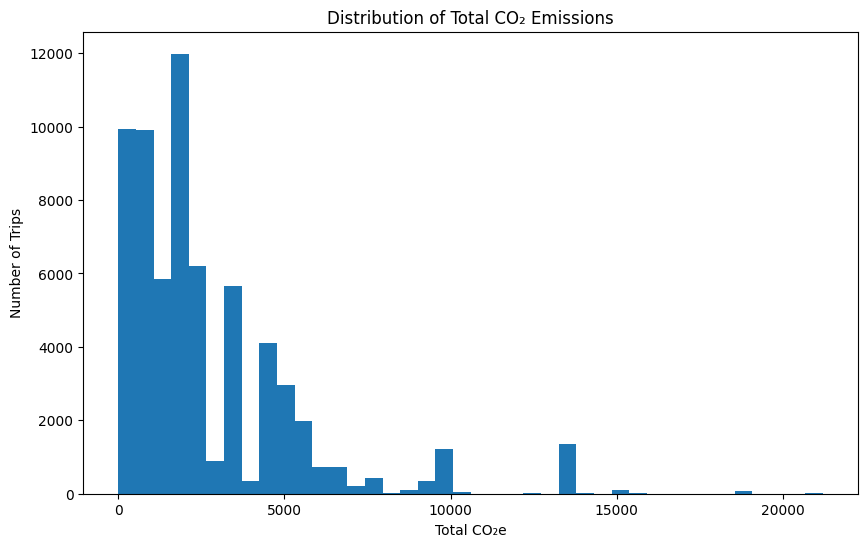

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.hist(
    trip_df["TotalCO2e"],
    bins=40
)

plt.title("Distribution of Total CO₂ Emissions")
plt.xlabel("Total CO₂e")
plt.ylabel("Number of Trips")

plt.show()

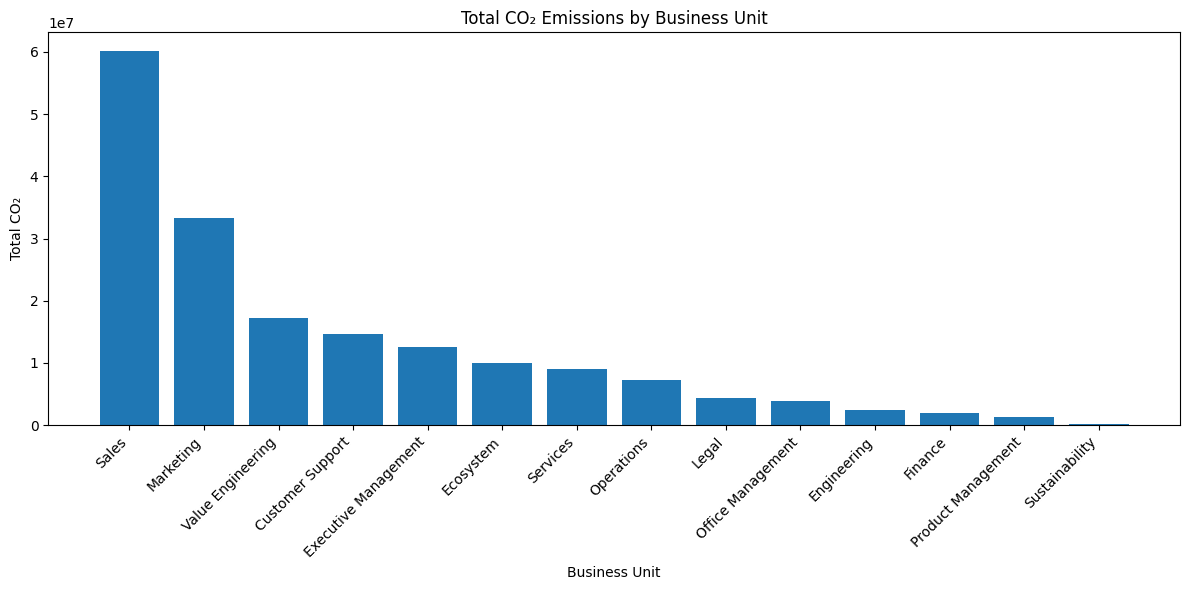

In [70]:
plt.figure(figsize=(12,6))

plt.bar(
    bu_emissions.index,
    bu_emissions["Total_CO2"]
)

plt.title("Total CO₂ Emissions by Business Unit")
plt.xlabel("Business Unit")
plt.ylabel("Total CO₂")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.show()

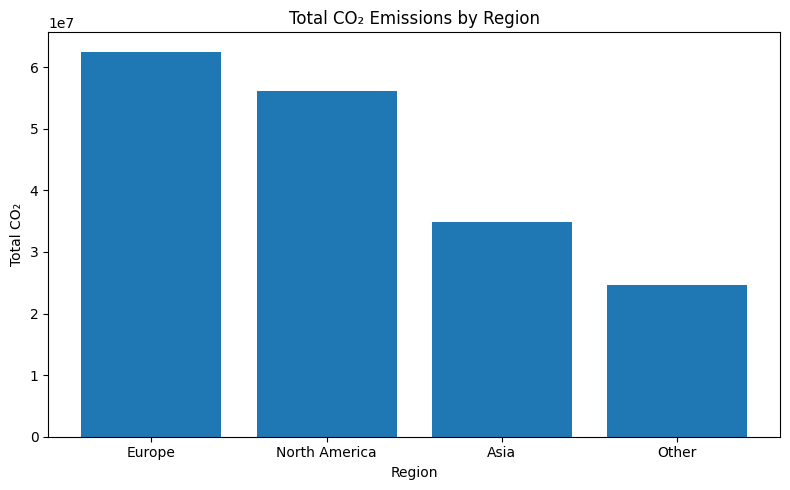

In [71]:
plt.figure(figsize=(8,5))

plt.bar(
    region_summary.index,
    region_summary["Total_CO2"]
)

plt.title("Total CO₂ Emissions by Region")
plt.xlabel("Region")
plt.ylabel("Total CO₂")

plt.tight_layout()

plt.show()

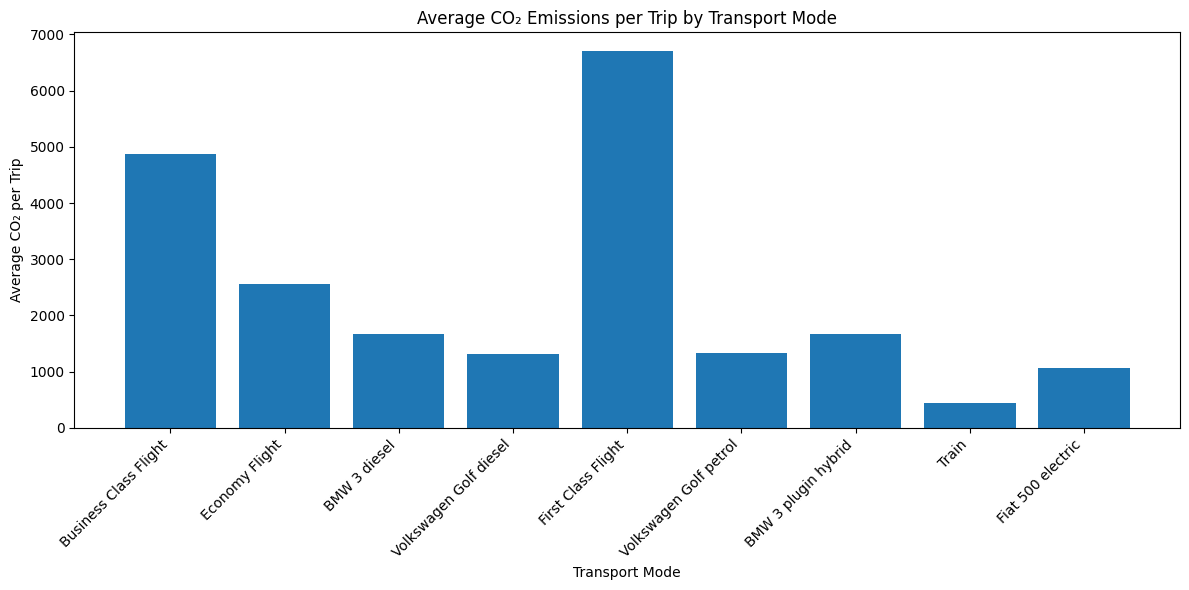

In [72]:
plt.figure(figsize=(12,6))

plt.bar(
    transport_summary.index,
    transport_summary["Average_CO2"]
)

plt.title("Average CO₂ Emissions per Trip by Transport Mode")
plt.xlabel("Transport Mode")
plt.ylabel("Average CO₂ per Trip")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.show()

# Executive Summary

## Key Findings

1. The dataset contains 65,289 business trips with a right-skewed emission distribution, indicating that a relatively small number of trips contribute disproportionately to total emissions.

2. Sales generates the highest total CO₂ emissions due to its large travel volume, while Sustainability and Ecosystem exhibit the highest emissions per trip.

3. Europe contributes the highest total emissions and has the highest proportion of HighCarbon trips, whereas Asia records the highest average emissions per trip.

4. Customer Visits account for the largest share of emissions because they represent the highest number of trips. Internal Business Trips have the highest average emissions per trip.

5. Business Class Flights contribute the highest total emissions, while First Class Flights have the highest average emissions per trip and the highest proportion of HighCarbon trips.

6. Train travel is the most environmentally sustainable transportation mode, with the lowest average emissions and no HighCarbon trips.

7. The Sydney → Frankfurt corridor is the highest-emitting travel route, followed by Sydney → Los Angeles.

8. Travel mode and travel distance appear to be stronger drivers of emissions than travel purpose.

## Business Recommendations

- Reduce premium-class air travel where feasible.
- Promote rail travel for short-distance journeys.
- Encourage electric or hybrid vehicle usage where appropriate.
- Prioritize emission reduction initiatives in Europe and high-volume Business Units such as Sales.
- Focus sustainability initiatives on high-emission routes and HighCarbon trips.

In [73]:
trip_attributes_path = "../Data/public/public_trip_event_attributes.csv"

In [74]:
trip_attributes_df = pd.read_csv(trip_attributes_path)

In [75]:
trip_attributes_path = "../Data/public/public_trip_event_attributes.csv"

# Quantified Sustainability Scenarios

## Scenario 1: Replace Short-Distance Flights with Rail

In [76]:
transport_summary = (
    trip_df.groupby("ShippingTypeDescription")
    .agg(
        Trips=("TripID", "count"),
        Total_CO2=("TotalCO2e", "sum"),
        Avg_CO2=("TotalCO2e", "mean"),
        Total_Cost=("NetCosts", "sum"),
        HighCarbon_Trips=("HighCarbon", "sum")
    )
    .sort_values("Total_CO2", ascending=False)
)

transport_summary

,Trips,Total_CO2,Avg_CO2,Total_Cost,HighCarbon_Trips
ShippingTypeDescription,,,,,
Business Class Flight,15035,7.314588e+07,4865.040043,32290500,8475
Economy Flight,27295,6.972636e+07,2554.546940,58599750,5836
BMW 3 diesel,6648,1.106429e+07,1664.303480,14380050,709
Volkswagen Golf diesel,5452,7.206012e+06,1321.719057,11906250,284
First Class Flight,973,6.520954e+06,6701.905821,2073150,612
Volkswagen Golf petrol,4469,5.965699e+06,1334.906859,9577500,238
BMW 3 plugin hybrid,1101,1.844558e+06,1675.347730,2365500,115
Train,3197,1.423949e+06,445.401670,6822750,0
Fiat 500 electric,1119,1.192391e+06,1065.585979,2463750,57


In [77]:
business_summary = (
    trip_df.groupby("BusinessUnit")
    .agg(
        Trips=("TripID","count"),
        Total_CO2=("TotalCO2e","sum"),
        Avg_CO2=("TotalCO2e","mean"),
        Total_Cost=("NetCosts","sum"),
        HighCarbon_Trips=("HighCarbon","sum")
    )
    .sort_values("Total_CO2",ascending=False)
)

business_summary

,Trips,Total_CO2,Avg_CO2,Total_Cost,HighCarbon_Trips
BusinessUnit,,,,,
Sales,21890,6.013901e+07,2747.328027,47078700,5532
Marketing,12238,3.337708e+07,2727.331176,26314200,3030
Value Engineering,6482,1.723755e+07,2659.295615,13971750,1576
Customer Support,5336,1.465835e+07,2747.066166,11561850,1344
Executive Management,4633,1.252706e+07,2703.875977,9853500,1139
Ecosystem,3492,9.971456e+06,2855.514178,7515750,937
Services,3313,8.960673e+06,2704.700443,7228200,838
Operations,2710,7.254383e+06,2676.893939,5804700,674
Legal,1611,4.349057e+06,2699.600868,3445950,399


In [78]:
purpose_summary = (
    trip_df.groupby("Purpose")
    .agg(
        Trips=("TripID","count"),
        Total_CO2=("TotalCO2e","sum"),
        Avg_CO2=("TotalCO2e","mean"),
        Total_Cost=("NetCosts","sum"),
        HighCarbon_Trips=("HighCarbon","sum")
    )
    .sort_values("Total_CO2",ascending=False)
)

purpose_summary

,Trips,Total_CO2,Avg_CO2,Total_Cost,HighCarbon_Trips
Purpose,,,,,
Customer Visit,28229,7.687956e+07,2723.424911,60652200,6985
Conference/Exhibition,23122,6.297606e+07,2723.642575,49741200,5829
Internal Business Trip,7416,2.043837e+07,2755.983660,16001250,1887
Enablement,4630,1.264808e+07,2731.767811,10029900,1150
Partner Visit,1892,5.148003e+06,2720.931913,4054650,475


In [79]:
region_summary = (
    trip_df.groupby("Region")
    .agg(
        Trips=("TripID","count"),
        Total_CO2=("TotalCO2e","sum"),
        Avg_CO2=("TotalCO2e","mean"),
        Total_Cost=("NetCosts","sum"),
        HighCarbon_Trips=("HighCarbon","sum")
    )
    .sort_values("Total_CO2",ascending=False)
)

region_summary

,Trips,Total_CO2,Avg_CO2,Total_Cost,HighCarbon_Trips
Region,,,,,
Europe,20421,6.251857e+07,3061.484320,43964400,7775
North America,19872,5.617250e+07,2826.716066,42774900,4148
Asia,11334,3.481845e+07,3072.035340,24343800,3092
Other,13662,2.458057e+07,1799.192425,29396100,1311


# High-Carbon Trip Prediction

## Load Training and Test Data

In [80]:
# Public data
public_trip = pd.read_csv("../Data/public/public_trip_data.csv")
public_event = pd.read_csv("../Data/public/public_trip_event_log.csv")
public_attr = pd.read_csv("../Data/public/public_trip_event_attributes.csv")

# Private data
private_trip = pd.read_csv("../Data/private/private_trip_data.csv")
private_event = pd.read_csv("../Data/private/private_trip_event_log.csv")
private_attr = pd.read_csv("../Data/private/private_trip_event_attributes.csv")

In [81]:
print("Public Trip:", public_trip.shape)
print("Private Trip:", private_trip.shape)

print("Public Event:", public_event.shape)
print("Private Event:", private_event.shape)

print("Public Attributes:", public_attr.shape)
print("Private Attributes:", private_attr.shape)

Public Trip: (65289, 20)
Private Trip: (21764, 13)
Public Event: (671547, 4)
Private Event: (223819, 4)
Public Attributes: (65289, 19)
Private Attributes: (21764, 18)


In [82]:
public_trip.head()

,TripID,DepartureLocationCountry,DepartureLocationCity,ArrivalLocationCountry,ArrivalLocationCity,ShippingType,ShippingTypeDescription,Purpose,OutOfPolicy,EntitiyCode,EmployeeNumber,BusinessUnit,HotelNights,NetCosts,Departure_CO2e,Return_CO2e,Hotel_CO2e,Spend_CO2e,TotalCO2e,HighCarbon
0,1,CN,Beijing,IN,New Delhi,12,Business Class Flight,Customer Visit,No,9000,M1000-M5008,Services,1,900,1565.121857,1565.121857,58.9,1472.279257,3189.143714,0
1,3,US,New York,MX,Mexico City,11,First Class Flight,Customer Visit,Yes,6000,M1000-M5030,Sales,2,3600,743.295848,743.295848,38.6,2921.504761,1525.191696,0
2,6,BR,SÃ£o Paulo,ZA,Johannesburg,10,Economy Flight,Conference/Exhibition,No,9000,M1000-M5069,Services,1,450,1053.713528,1053.713528,51.4,743.646219,2158.827056,0
3,7,DE,Berlin,FR,Paris,12,Business Class Flight,Customer Visit,No,10000,M1000-M5095,Executive Management,1,3450,196.262703,196.262703,6.7,3343.160260,399.225407,0
4,8,BR,SÃ£o Paulo,ZA,Johannesburg,10,Economy Flight,Internal Business Trip,No,7000,M1000-M5097,Marketing,2,1500,1053.713528,1053.713528,102.8,2478.820729,2210.227056,0


In [83]:
private_trip.head()

,TripID,DepartureLocationCountry,DepartureLocationCity,ArrivalLocationCountry,ArrivalLocationCity,ShippingType,ShippingTypeDescription,Purpose,OutOfPolicy,EntitiyCode,BusinessUnit,HotelNights,NetCosts
0,2,BR,SÃ£o Paulo,ZA,Johannesburg,12,Business Class Flight,Customer Visit,Yes,8000,Sales,6,2400
1,4,CN,Beijing,GB,London,10,Economy Flight,Internal Business Trip,No,8000,Customer Support,3,3150
2,5,AU,Sydney,US,Los Angeles,10,Economy Flight,Conference/Exhibition,No,8000,Marketing,6,3000
3,14,BR,SÃ£o Paulo,US,Miami,10,Economy Flight,Conference/Exhibition,No,8000,Executive Management,2,1350
4,15,DE,Berlin,ES,Madrid,12,Business Class Flight,Conference/Exhibition,Yes,8000,Marketing,2,2850


In [84]:
# Features common to both train and test
common_features = [
    "DepartureLocationCountry",
    "DepartureLocationCity",
    "ArrivalLocationCountry",
    "ArrivalLocationCity",
    "ShippingType",
    "ShippingTypeDescription",
    "Purpose",
    "OutOfPolicy",
    "EntitiyCode",
    "BusinessUnit",
    "HotelNights",
    "NetCosts"
]

X = public_trip[common_features].copy()
y = public_trip["HighCarbon"]

X_test = private_trip[common_features].copy()

print("Training Features:", X.shape)
print("Training Labels:", y.shape)
print("Test Features:", X_test.shape)

Training Features: (65289, 12)
Training Labels: (65289,)
Test Features: (21764, 12)


In [85]:
X.dtypes

DepartureLocationCountry      str
DepartureLocationCity         str
ArrivalLocationCountry        str
ArrivalLocationCity           str
ShippingType                int64
ShippingTypeDescription       str
Purpose                       str
OutOfPolicy                   str
EntitiyCode                 int64
BusinessUnit                  str
HotelNights                 int64
NetCosts                    int64
dtype: object

In [86]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

categorical_features = [
    "DepartureLocationCountry",
    "DepartureLocationCity",
    "ArrivalLocationCountry",
    "ArrivalLocationCity",
    "ShippingTypeDescription",
    "Purpose",
    "OutOfPolicy",
    "BusinessUnit"
]

numeric_features = [
    "ShippingType",
    "EntitiyCode",
    "HotelNights",
    "NetCosts"
]

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", categorical_transformer, categorical_features),
        ("num", numeric_transformer, numeric_features)
    ]
)

print("Preprocessor Created Successfully")

Preprocessor Created Successfully


In [87]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

pred = rf_model.predict(X_valid)

print("Accuracy:", accuracy_score(y_valid, pred))
print()
print(classification_report(y_valid, pred))

Accuracy: 0.9915760453361924

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      9793
           1       0.98      0.98      0.98      3265

    accuracy                           0.99     13058
   macro avg       0.99      0.99      0.99     13058
weighted avg       0.99      0.99      0.99     13058



In [88]:
from sklearn.metrics import roc_auc_score

probabilities = rf_model.predict_proba(X_valid)[:, 1]

roc = roc_auc_score(y_valid, probabilities)

print("ROC-AUC Score:", roc)

ROC-AUC Score: 0.9975716942548426


In [89]:
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

importances = rf_model.named_steps["classifier"].feature_importances_

importance_df = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })
    .sort_values("Importance", ascending=False)
)

importance_df.head(20)

,Feature,Importance
45,cat__ArrivalLocationCity_Frankfurt,0.101696
67,cat__ShippingTypeDescription_Business Class Fl...,0.101086
23,cat__ArrivalLocationCountry_DE,0.091483
95,num__ShippingType,0.076135
97,num__HotelNights,0.042957
68,cat__ShippingTypeDescription_Economy Flight,0.032544
0,cat__DepartureLocationCountry_AU,0.031214
17,cat__DepartureLocationCity_Sydney,0.030098
3,cat__DepartureLocationCountry_DE,0.018970
10,cat__DepartureLocationCity_Berlin,0.018668


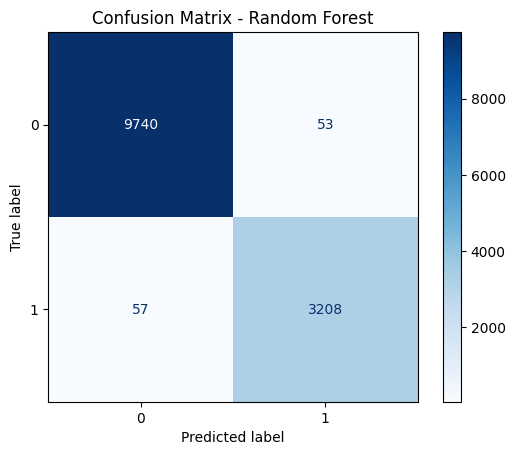

In [90]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(
    rf_model,
    X_valid,
    y_valid,
    cmap="Blues"
)

plt.title("Confusion Matrix - Random Forest")
plt.show()

In [91]:
# Predict probabilities on the private test data

test_probabilities = rf_model.predict_proba(X_test)[:, 1]

test_predictions = rf_model.predict(X_test)

print(test_probabilities[:10])
print(test_predictions[:10])

[1.    0.    0.97  0.    0.    0.    1.    0.995 0.    0.   ]
[1 0 1 0 0 0 1 1 0 0]


In [92]:
submission = pd.DataFrame({
    "TripID": private_trip["TripID"],
    "HighCarbon": test_predictions
})

submission.head()

,TripID,HighCarbon
0,2,1
1,4,0
2,5,1
3,14,0
4,15,0


In [93]:
submission.to_csv("submission_random_forest.csv", index=False)

print("Submission file created successfully!")

Submission file created successfully!


# Quantified Sustainability Recommendations

In [94]:
business = transport_summary.loc["Business Class Flight"]
economy = transport_summary.loc["Economy Flight"]

business

Trips               1.503500e+04
Total_CO2           7.314588e+07
Avg_CO2             4.865040e+03
Total_Cost          3.229050e+07
HighCarbon_Trips    8.475000e+03
Name: Business Class Flight, dtype: float64

In [95]:
business_avg = business["Avg_CO2"]
economy_avg = economy["Avg_CO2"]

co2_saved_per_trip = business_avg - economy_avg

co2_saved_per_trip

np.float64(2310.493102883612)

In [96]:
business_trips = business["Trips"]

shift_20 = business_trips * 0.20

shift_20

np.float64(3007.0)

In [97]:
total_saved = shift_20 * co2_saved_per_trip

print(total_saved)

6947652.760371022
